# Fase 03 : Aplicación del entorno de simulación y entrenamiento
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Octubre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Aplicación del entorno de simulación y entrenamiento del modelo
* **Fase del Proyecto:** Tercera fase fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [1]:
import polars as pl
import s_01_functions as fn_01
from pyprojroot import here
from s_02_stock_env import EntornoInventario
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.monitor import Monitor
from datetime import date
from stable_baselines3.common.logger import configure

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

In [2]:
df_02 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_02.parquet')
df_02.glimpse()

Rows: 17239
Columns: 11
$ bottle_volume_ml  <enum> 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750
$ category_name      <cat> CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES
$ im_desc            <cat> BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET
$ item_no            <i64> 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788
$ ordered_on        <date> 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack               <i64> 6, 6, 6, 6, 6, 6, 6, 6, 6, 6
$ period_ordered_on  <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ product_code       <str> 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205

<h3 style="color:#05856d">3. Preparación de datos</h3>
<hr>

<h4 style="color:#05856d">3.1. Ajustar la demanda y otras variables</h4>

In [3]:
# Creación de calendario
df_calendario = pl.DataFrame(
    {'ordered_on': pl.date_range(
        start = df_02['ordered_on'].min(), 
        end = df_02['ordered_on'].max(),
        interval = '1d',
        eager = True)} )

# Acoplar la demanda al caledario previamente creado
df_demanda_continua = (
    df_calendario
    .join( other = df_02.group_by('ordered_on').agg(pl.sum('sales_bottles').alias('demanda_diaria')),
           on = 'ordered_on', 
           how = 'left' )
    .with_columns([ pl.col('demanda_diaria').fill_null(0),                 
                    pl.col('ordered_on').dt.weekday().alias('dia_semana') ]) )

# Cantidad de botellas por pack
pack_u = df_02['pack'][0]

# Precio unitario promedio
precio_u = (df_02['sales_dollars'] / df_02['sales_bottles']).mean()

<h4 style="color:#05856d">3.2. Datos de entrenamiento y prueba</h4>

Se divide cronológicamente los datos el dataset. Por tanto, no es necesaria una semilla aleatoria.

In [4]:
df_train = df_demanda_continua.filter(pl.col('ordered_on') < date(2026,7,1))
df_test = df_demanda_continua.filter(pl.col('ordered_on') >= date(2026,7,1))

print(f"Total de días reales en el calendario: {df_demanda_continua.height}")
print('-'*60)
print(f"Registros para el conjunto de entrenamiento (Train): {df_train.height}")
print(f"Proporción del conjunto de entrenamiento: {df_train.height/df_demanda_continua.height:.2f}")
print('-'*60)
print(f"Registros para prueba (Test): {df_test.height}")
print(f"Proporción del conjunto de prueba: {df_test.height / df_demanda_continua.height:.2f}")

Total de días reales en el calendario: 242
------------------------------------------------------------
Registros para el conjunto de entrenamiento (Train): 180
Proporción del conjunto de entrenamiento: 0.74
------------------------------------------------------------
Registros para prueba (Test): 62
Proporción del conjunto de prueba: 0.26


Configuración de los entornos de entrenamiento y prueba. En este punto se instancia la "arquitectura" para que cualquier algoritmo de aprendizaje por refuerzo pueda funcionar.

In [5]:
print('Configurando Entorno de ENTRENAMIENTO...')
env_training = EntornoInventario(
    df_demanda_diaria = df_train,          
    precio_unitario = precio_u,  
    tamano_pack = pack_u )

print('Configurando Entorno de PRUEBAS...')
env_testing = EntornoInventario(
    df_demanda_diaria = df_test,     
    precio_unitario = precio_u,  
    tamano_pack = pack_u )

Configurando Entorno de ENTRENAMIENTO...
Configurando Entorno de PRUEBAS...


<h3 style="color:#05856d">4. Entrenamiento del modelo</h3>
<hr>
Construcción de la red neuronal a través del algoritmo Proximal Policy Optimization (PPO)

In [23]:

# 1. Inicio
print('Inicializando la Red Neuronal PPO (Entrenamiento sobre df_train)...')

# 2. Configurar la bitácora
# "stdout" (para seguir viéndolo en consola) y "csv" (para la tabla)
file_logger = configure(
    folder = str(here() / '04_tables_models' / 's_04_01_agent_ppo_log'),
    # format_strings = ['stdout', 'csv']
    format_strings = ['csv']
    )

# Monitor permite registrar las estadísticas correctamente
env_monitoreado = Monitor(env_training)
# DummyVecEnv es el formato vectorial requerido por Stable Baselines3
env_vectorizado = DummyVecEnv([lambda: env_monitoreado])
# VecNormalize estandariza Observaciones y Recompensas al vuelo
env_normalizado = VecNormalize(env_vectorizado, norm_obs=True, norm_reward=True, clip_obs=10.0)


# MlpPolicy (Perceptrón Multicapa), ideal para vectores de números.
modelo_ppo_final = PPO(
    policy = 'MlpPolicy', 
    env = env_normalizado,     # Se usa SOLO el entorno de entrenamiento
    verbose = 1,            # Para ver el progreso en la consola
    seed = 42,              # Semilla de reproducibilidad
    ent_coef = 0.01,        # Coeficiente de entropía: fomenta la exploración de estrategias
    learning_rate = 0.0002  # Tasa de aprendizaje estable
)

# 2. Entrenamiento
modelo_ppo_final.set_logger(file_logger) # Configurar antes de entrenar
print('\nIniciando entrenamiento de 1,000,000 de timesteps.')
modelo_ppo_final.learn(total_timesteps = 1000000)

# 3. Guardar el "Cerebro" entrenado
modelo_ppo_final.save(path = here()/'04_tables_models'/'s_04_01_agent_ppo' )
env_normalizado.save(save_path = here()/'04_tables_models'/'vec_normalize_stats.pkl' )

env_training.close()

Inicializando la Red Neuronal PPO (Entrenamiento sobre df_train)...
Using cpu device

Iniciando entrenamiento de 1,000,000 de timesteps.


<h3 style="color:#05856d">5. Revisar entrenamiento</h3>
<hr>

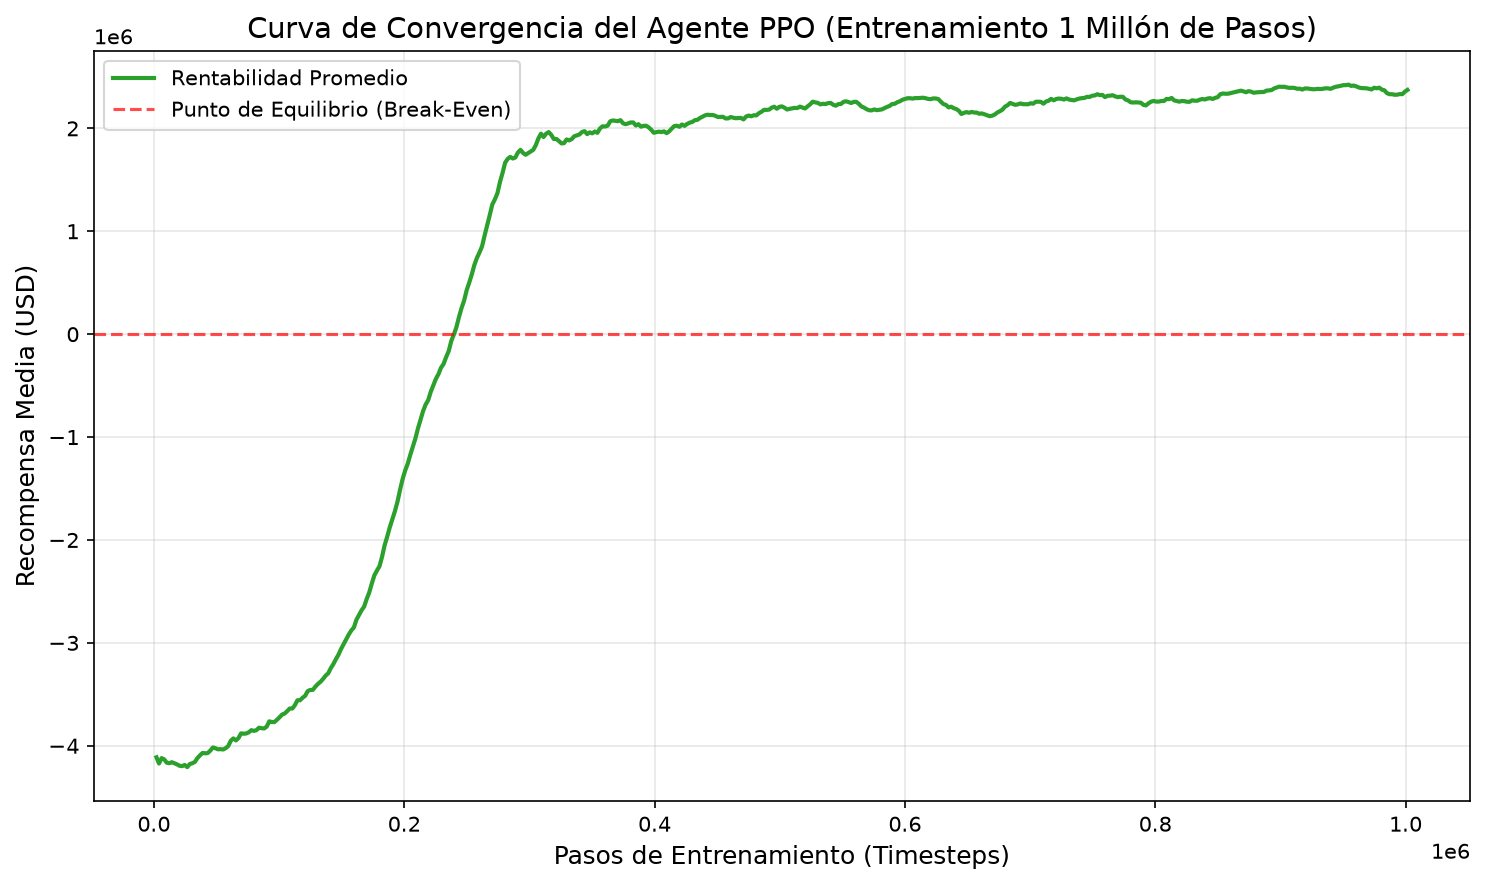

In [9]:
import matplotlib.pyplot as plt

# 1. Cargar la bitácora CSV con Polars
df_logs = pl.read_csv( here()/'04_tables_models'/'s_04_01_agent_ppo_log'/'progress.csv' )

# 2. Extraer las coordenadas (Eje X: Tiempo, Eje Y: Recompensa Media)
pasos = df_logs["time/total_timesteps"]
recompensa = df_logs["rollout/ep_rew_mean"]

# 3. Graficar la Curva de Aprendizaje
plt.figure(figsize=(10, 6))
plt.plot(pasos, recompensa, color='#2ca02c', linewidth=2, label='Rentabilidad Promedio')

plt.title('Curva de Convergencia del Agente PPO (Entrenamiento 1 Millón de Pasos)', fontsize=14)
plt.xlabel('Pasos de Entrenamiento (Timesteps)', fontsize=12)
plt.ylabel('Recompensa Media (USD)', fontsize=12)

# Añadir una línea en y=0 para ver en qué momento dejó de perder dinero y empezó a ser rentable
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Punto de Equilibrio (Break-Even)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('curva_convergencia_tesis.png', dpi=300)
plt.show()

<h3 style="color:#05856d">6. Comparar resultados</h3>
<hr>

🧠 Cargando al Súper Agente PPO Normalizado...
📊 Ejecutando 50 simulaciones estocásticas en el conjunto de PRUEBA (Test)...

📈 RESULTADOS DEL CONTRASTE DE MEDIAS (50 Simulaciones)
💰 Media Beneficio PPO: $441,914.84 (Desv: $36,227.07)
💰 Media Beneficio EOQ: $354,467.39 (Desv: $225,744.95)
------------------------------------------------------------
⚖️ T-Statistic: 2.6774
🔬 P-Value:     9.9302e-03
✅ CONCLUSIÓN: El Agente PPO es estadísticamente SUPERIOR al EOQ (p < 0.05).


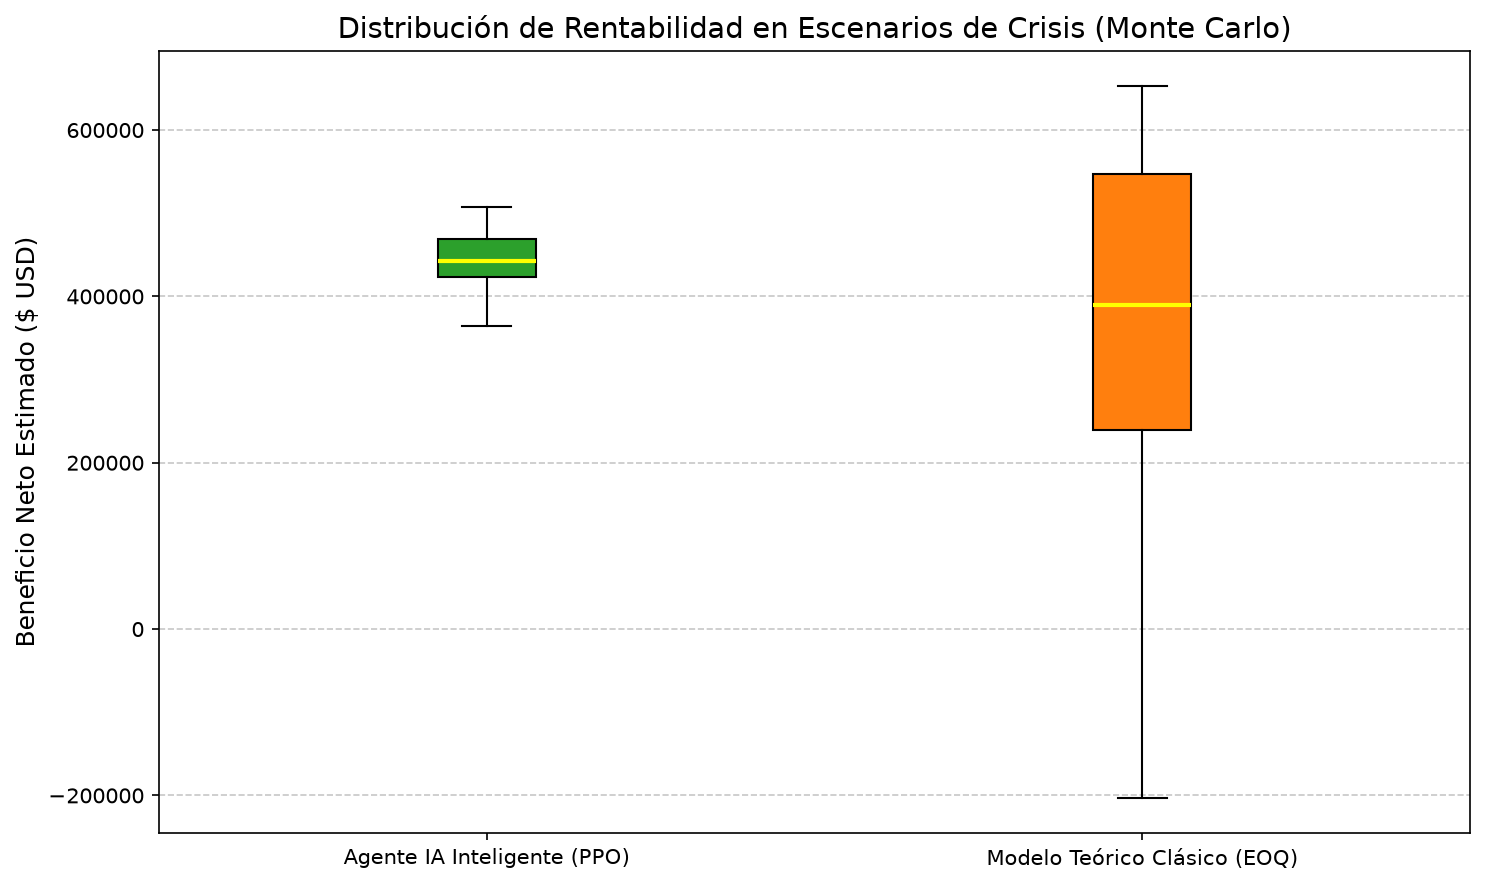

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from pyprojroot import here # Nos aseguramos de que esté importado

print("🧠 Cargando al Súper Agente PPO Normalizado...")

# 1. Envolver en str() para evitar el AssertionError de rutas
ruta_modelo = str(here() / '04_tables_models' / 's_04_01_agent_ppo')
modelo_cargado = PPO.load(ruta_modelo)

# INYECTANDO LA NORMALIZACIÓN AL ENTORNO DE PRUEBAS (TEST)
# 1. Vectorizamos el entorno de prueba
env_test_vec = DummyVecEnv([lambda: env_testing])

# 2. Envolver en str() la ruta de las estadísticas matemáticas
ruta_stats = str(here() / '04_tables_models' / 'vec_normalize_stats.pkl')
env_test_norm = VecNormalize.load(ruta_stats, env_test_vec)

# Desactivamos la actualización de la normalización (¡es un examen, no puede seguir aprendiendo!)
env_test_norm.training = False
env_test_norm.norm_reward = False # Devuelve los dólares reales

num_simulaciones = 50
resultados_ppo = []
resultados_eoq = []

# Parámetros del EOQ Teórico
q_optimo_packs = 640
punto_reorden_botellas = 4200

print(f"📊 Ejecutando {num_simulaciones} simulaciones estocásticas en el conjunto de PRUEBA (Test)...")

for i in range(num_simulaciones):
    semilla = 42 + i
    
    # --- 1. SIMULACIÓN PPO ---
    # CORRECCIÓN: Usamos el método nativo de SB3 para pasar la semilla al entorno vectorizado
    env_test_norm.seed(semilla) 
    obs = env_test_norm.reset()
    
    terminado = False
    beneficio_ppo_iter = 0.0
    
    # En entornos vectorizados, 'dones' y 'recompensa' son arreglos
    while not terminado:
        action, _ = modelo_cargado.predict(obs, deterministic=True)
        obs, recompensa, dones, info = env_test_norm.step(action)
        
        # Como norm_reward=False, recompensa ya es el valor financiero real
        beneficio_ppo_iter += recompensa[0]
        terminado = dones[0]
        
    resultados_ppo.append(beneficio_ppo_iter)
    
    # --- 2. SIMULACIÓN EOQ (CORREGIDA CON EL CANDADO LOGÍSTICO) ---
    # Usamos el entorno CRUDO para el EOQ (no necesita normalización)
    obs_raw, _ = env_testing.reset(seed=semilla)
    terminado_raw = False
    beneficio_eoq_iter = 0.0
    
    pedido_en_camino = False
    inventario_anterior = obs_raw[0]
    
    while not terminado_raw:
        inventario_actual = obs_raw[0]
        
        if inventario_actual > inventario_anterior:
            pedido_en_camino = False
            
        if inventario_actual <= punto_reorden_botellas and not pedido_en_camino:
            action = q_optimo_packs
            pedido_en_camino = True
        else:
            action = 0
            
        inventario_anterior = inventario_actual
        obs_raw, recompensa_raw, terminado_raw, truncado_raw, info_raw = env_testing.step(action)
        beneficio_eoq_iter += recompensa_raw
        
    resultados_eoq.append(beneficio_eoq_iter)

# --- ANÁLISIS ESTADÍSTICO ---
resultados_ppo = np.array(resultados_ppo)
resultados_eoq = np.array(resultados_eoq)

t_stat, p_value = stats.ttest_ind(resultados_ppo, resultados_eoq, equal_var=False)

print("\n" + "=" * 60)
print("📈 RESULTADOS DEL CONTRASTE DE MEDIAS (50 Simulaciones)")
print("=" * 60)
print(f"💰 Media Beneficio PPO: ${resultados_ppo.mean():,.2f} (Desv: ${resultados_ppo.std():,.2f})")
print(f"💰 Media Beneficio EOQ: ${resultados_eoq.mean():,.2f} (Desv: ${resultados_eoq.std():,.2f})")
print("-" * 60)
print(f"⚖️ T-Statistic: {t_stat:.4f}")
print(f"🔬 P-Value:     {p_value:.4e}")

if p_value < 0.05:
    if resultados_ppo.mean() > resultados_eoq.mean():
        print("✅ CONCLUSIÓN: El Agente PPO es estadísticamente SUPERIOR al EOQ (p < 0.05).")
    else:
        print("⚠️ CONCLUSIÓN: El EOQ es estadísticamente SUPERIOR al PPO (p < 0.05).")
else:
    print("🤷‍♂️ CONCLUSIÓN: No hay diferencia estadísticamente significativa entre los modelos.")
print("=" * 60)

# --- GRÁFICO BOXPLOT PARA LA TESIS ---
plt.figure(figsize=(10, 6))
cajas = plt.boxplot([resultados_ppo, resultados_eoq], 
            patch_artist=True, boxprops=dict(facecolor='#2ca02c', color='black'), 
            medianprops=dict(color='yellow', linewidth=2))

cajas['boxes'][1].set_facecolor('#ff7f0e') 
plt.xticks([1, 2], ['Agente IA Inteligente (PPO)', 'Modelo Teórico Clásico (EOQ)'])

plt.title('Distribución de Rentabilidad en Escenarios de Crisis (Monte Carlo)', fontsize=14)
plt.ylabel('Beneficio Neto Estimado ($ USD)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Guardamos aplicando el str() por si acaso
ruta_grafico = str(here() / '04_tables_models' / 'boxplot_definitivo_tesis.png')
plt.savefig(ruta_grafico, dpi=300)
plt.show()